In [1]:
%pip install -q "qiskit==2.2.3" "qiskit-machine-learning==0.9.0" "qiskit-algorithms==0.4.0" "koreanize-matplotlib==0.1.1"

import sys
from importlib.metadata import version
print("Python:", sys.version.split()[0])
for name in ["qiskit", "qiskit-machine-learning", "qiskit-algorithms", "torch", "numpy", "scipy"]:
    print(name, version(name))
from qiskit.primitives import StatevectorEstimator
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.connectors import TorchConnector
print("설치 및 import 확인 완료")

Python: 3.13.18
qiskit 2.2.3
qiskit-machine-learning 0.9.0
qiskit-algorithms 0.4.0
torch 2.11.0+cpu
numpy 2.1.3
scipy 1.16.3
설치 및 import 확인 완료


Epoch 001 | Loss: 0.8158 | Acc: 54.0%
Epoch 010 | Loss: 0.4658 | Acc: 86.0%
Epoch 020 | Loss: 0.3721 | Acc: 100.0%
Epoch 030 | Loss: 0.3669 | Acc: 96.0%
Epoch 040 | Loss: 0.3639 | Acc: 96.0%
Epoch 050 | Loss: 0.3619 | Acc: 98.0%
Epoch 060 | Loss: 0.3613 | Acc: 98.0%
Epoch 070 | Loss: 0.3615 | Acc: 98.0%
Epoch 080 | Loss: 0.3613 | Acc: 98.0%

[최종 결과]
정확도: 98.0 %
예측 확률 p: [0.833 0.361 0.825 0.301 0.8   0.538 0.788 0.26  0.677 0.705 0.255 0.693
 0.392 0.751 0.418 0.745 0.271 0.719 0.308 0.715 0.754 0.279 0.45  0.753
 0.771 0.288 0.79  0.363 0.676 0.727 0.3   0.349 0.716 0.296 0.797 0.462
 0.762 0.362 0.697 0.661 0.234 0.771 0.436 0.745 0.335 0.717 0.477 0.775
 0.322 0.772]
예측 레이블: [1 0 1 0 1 1 1 0 1 1 0 1 0 1 0 1 0 1 0 1 1 0 0 1 1 0 1 0 1 1 0 0 1 0 1 0 1
 0 1 1 0 1 0 1 0 1 0 1 0 1]
실제 레이블: [1. 0. 1. 0. 1. 0. 1. 0. 1. 1. 0. 1. 0. 1. 0. 1. 0. 1. 0. 1. 1. 0. 0. 1.
 1. 0. 1. 0. 1. 1. 0. 0. 1. 0. 1. 0. 1. 0. 1. 1. 0. 1. 0. 1. 0. 1. 0. 1.
 0. 1.]


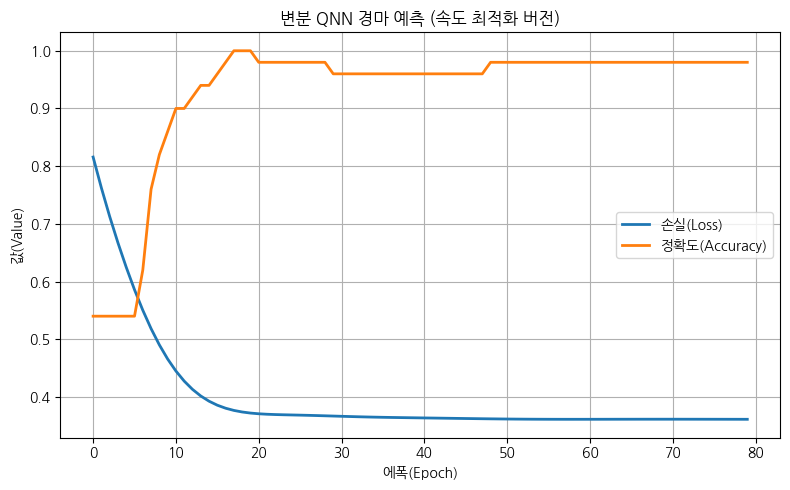

In [4]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import koreanize_matplotlib

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp
from qiskit.primitives import StatevectorEstimator
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.connectors import TorchConnector

# -----------------------------------------------------
# 0) 재현성
# -----------------------------------------------------
os.environ["PYTHONHASHSEED"] = "0"
np.random.seed(42)
torch.manual_seed(42)

# -----------------------------------------------------
# 1) 경마 데이터 (평균속도, 최근순위)
# -----------------------------------------------------
data = np.array([
    [58.3,2.1,1],[55.8,5.4,0],[60.5,1.7,1],[54.2,6.1,0],[61.7,1.3,1],
    [56.5,4.2,0],[59.1,2.4,1],[52.9,7.2,0],[63.5,1.5,1],[57.3,3.1,1],
    [53.6,6.8,0],[62.8,2.0,1],[50.5,8.4,0],[59.8,2.6,1],[55.9,5.0,0],
    [62.1,1.8,1],[54.5,6.3,0],[57.9,3.0,1],[51.7,7.8,0],[63.0,1.4,1],
    [60.9,2.3,1],[52.3,7.5,0],[55.1,4.8,0],[58.9,2.7,1],[59.4,2.5,1],
    [53.4,6.5,0],[61.5,1.6,1],[50.8,8.7,0],[57.5,3.3,1],[62.3,1.9,1],
    [54.7,6.0,0],[55.6,5.5,0],[59.7,2.9,1],[52.1,7.4,0],[60.2,2.1,1],
    [56.1,4.7,0],[61.9,1.7,1],[50.9,8.1,0],[63.2,1.5,1],[57.8,3.4,1],
    [53.9,6.9,0],[60.7,2.2,1],[55.2,4.9,0],[58.4,2.8,1],[51.3,7.9,0],
    [62.6,1.8,1],[56.0,4.6,0],[61.3,1.9,1],[53.2,6.2,0],[59.9,2.4,1]
], dtype=np.float32)

X_raw = data[:, :2]
y_np = data[:, 2].reshape(-1,1)

# 정규화
X_np = np.column_stack((
    0.05 + 0.9 * ((X_raw[:,0] - 50) / 15.0),
    0.05 + 0.9 * (1 - (X_raw[:,1] / 9.0))
))

X = torch.tensor(X_np, dtype=torch.float32)
y = torch.tensor(y_np, dtype=torch.float32)

# -----------------------------------------------------
# 2) 양자 회로 (2-Layer 변분 구조)
# -----------------------------------------------------
num_qubits = 2
x_params = ParameterVector("x", length=2)
theta = ParameterVector("θ", length=8)

qc = QuantumCircuit(num_qubits)
# 입력 인코딩
qc.ry(np.pi * x_params[0], 0)
qc.ry(np.pi * x_params[1], 1)

# 1층 얽힘 + 가중치
qc.cx(0, 1)
qc.ry(theta[0], 0)
qc.rz(theta[1], 0)
qc.ry(theta[2], 1)
qc.rz(theta[3], 1)

# 2층 얽힘 + 가중치
qc.cx(1, 0)
qc.ry(theta[4], 0)
qc.rz(theta[5], 0)
qc.ry(theta[6], 1)
qc.rz(theta[7], 1)

# -----------------------------------------------------
# 3) Observable 설정 (ZI 단일화로 속도 최적화)
# -----------------------------------------------------
obs = SparsePauliOp.from_list([("ZI", 1.0)])

# -----------------------------------------------------
# 4) EstimatorQNN 및 TorchConnector
# -----------------------------------------------------
primitive = StatevectorEstimator(default_precision=0.0, seed=42)
qnn = EstimatorQNN(
    circuit=qc,
    observables=obs,
    input_params=list(x_params),
    weight_params=list(theta),
    estimator=primitive,
    default_precision=0.0,
    input_gradients=True,
)

model = TorchConnector(qnn)

# -----------------------------------------------------
# 5) 학습 설정
# -----------------------------------------------------
criterion = nn.BCELoss()
optimizer = optim.AdamW(model.parameters(), lr=0.05, weight_decay=0.01)
epochs = 80

losses, accuracies = [], []

# -----------------------------------------------------
# 6) 최적화된 학습 루프 (Full-batch 전송으로 오버헤드 제거)
# -----------------------------------------------------
for epoch in range(1, epochs + 1):
    model.train()
    optimizer.zero_grad()

    # 전체 데이터 한 번에 순전파
    out_expect = model(X)                          # shape: [50, 1]
    prob = ((out_expect + 1.0) / 2.0).clamp(1e-6, 1-1e-6)

    loss = criterion(prob, y)
    loss.backward()
    optimizer.step()

    with torch.no_grad():
        preds = (prob >= 0.5).float()
        acc = preds.eq(y).float().mean().item()

    losses.append(loss.item())
    accuracies.append(acc)

    if epoch % 10 == 0 or epoch == 1:
        print(f"Epoch {epoch:03d} | Loss: {loss.item():.4f} | Acc: {acc*100:.1f}%")

# -----------------------------------------------------
# 7) 평가
# -----------------------------------------------------
model.eval()
with torch.no_grad():
    out_expect = model(X)
    prob = ((out_expect + 1.0) / 2.0).clamp(1e-6, 1-1e-6)
    y_pred = (prob >= 0.5).float()

print("\n[최종 결과]")
print("정확도:", round((y_pred.eq(y).float().mean().item() * 100), 2), "%")
print("예측 확률 p:", prob.numpy().round(3).flatten())
print("예측 레이블:", y_pred.numpy().astype(int).flatten())
print("실제 레이블:", y_np.flatten())

# -----------------------------------------------------
# 8) 시각화
# -----------------------------------------------------
plt.figure(figsize=(8,5))
plt.plot(losses, label="손실(Loss)", linewidth=2)
plt.plot(accuracies, label="정확도(Accuracy)", linewidth=2)
plt.title("변분 QNN 경마 예측 (속도 최적화 버전)")
plt.xlabel("에폭(Epoch)")
plt.ylabel("값(Value)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("vqe_horse_fast_training.png", dpi=300)
plt.show()